# 05 · Публичная траектория: EPWA и ENT73JH

**Исследовательский вопрос:** Согласуются ли публичные наблюдения с координатами и временем C40 выбранного рейса?

**Входные материалы:** извлеченные state vectors OpenSky и метаданные ENT73JH_21100

Расчеты ниже выполняются в ячейках. Все исходные строки сохраняются. Округление таблиц используется только для чтения результатов.

In [1]:
# Подключаем библиотеки и находим корень проекта
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
# Подключаем проверенные геодезические функции без запуска скриптов
sys.path.insert(0, str(root/'europe/scripts'))
from audit_c40_radial_cases import ellipsoid_distance, validate_distance
from investigate_c40_geometry import distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})
# Таблицы округляем только при отображении, расчетные значения сохраняем
pd.set_option('display.max_columns', 14)


## 1. Читаем последовательность и проверяем свежесть

Работаем с ранее извлеченными наблюдениями. Контрольные суммы и URL архивов показаны отдельно. Центр EPWA восстановлен из метаданных; исторический ARP пока не подтвержден.

In [2]:
# Читаем оба часа и ограничиваем последовательность временем посадки плюс две минуты
case = pd.read_csv(study/'reports/05_public_monday_candidates.csv').set_index('flight_id').loc['ENT73JH_21100']
track = pd.concat([pd.read_csv(study/f'data/public_pilot/ENT73JH_21100_state_vectors{s}.csv')
                   for s in ['', '_23']],ignore_index=True).sort_values('time')
t = pd.Timestamp(case.C40_CROSS_TIME)
landing = pd.Timestamp(case.landing_time)
track['utc'] = pd.to_datetime(track.time,unit='s',utc=True)
track = track[track.utc <= landing+pd.Timedelta(minutes=2)].copy()
track['offset_s'] = (track.utc-t).dt.total_seconds()
track['position_age_s'] = track.time-track.lastposupdate
track['contact_age_s'] = track.time-track.lastcontact
display(track[['utc','lat','lon','callsign','position_age_s','contact_age_s']].head())
display(track[['position_age_s','contact_age_s']].describe().round(3))
# Показываем происхождение архивов без повторной загрузки
for suffix in ['', '_23']:
    manifest = json.loads((study/f'reports/05_public_pilot_download{suffix}.json').read_text(encoding='utf8'))
    display(manifest)

,utc,lat,lon,callsign,position_age_s,contact_age_s
0,2019-10-21 22:00:10+00:00,49.900085,13.841472,ENT73JH,0.127,0.002
1,2019-10-21 22:00:20+00:00,49.917252,13.864457,ENT73JH,0.133,0.009
2,2019-10-21 22:00:30+00:00,49.934097,13.887008,ENT73JH,0.342,0.068
3,2019-10-21 22:00:40+00:00,49.951436,13.910250,ENT73JH,0.110,0.002
4,2019-10-21 22:00:50+00:00,49.968939,13.933708,ENT73JH,0.091,0.006


,position_age_s,contact_age_s
count,386.000,386.000
mean,0.288,0.067
std,0.908,0.134
min,0.000,0.000
25%,0.039,0.010
50%,0.130,0.028
75%,0.230,0.073
max,8.271,1.800


{'url': 'https://s3.opensky-network.org/data-samples/states/.2019-10-21/22/states_2019-10-21-22.csv.tar',
 'checked_utc': '2026-10-09T17:27:57.472656+00:00',
 'bytes': 151121920,
 'sha256': '6f9e2396d2679054e409b6635ee0493f77408aad75b87cd716a61f796449e340',
 'catalog_etag': '"cfd1de73bb095d097a55b8d01bf9aa8d"',
 'archive': 'data\\public_pilot\\states_2019-10-21-22.csv.tar',
 'status': 'downloaded',
 'scanned_rows': 2399281,
 'aircraft': '489221',
 'selected_rows': 359,
 'selected_file': 'data\\public_pilot\\ENT73JH_21100_state_vectors.csv'}

{'url': 'https://s3.opensky-network.org/data-samples/states/.2019-10-21/23/states_2019-10-21-23.csv.tar',
 'checked_utc': '2026-10-09T17:51:02.366568+00:00',
 'bytes': 138301440,
 'sha256': '6213843ab3689522f0569f26f2c81d3024d2f796277914b3d2ba264073aaf89c',
 'catalog_etag': '"68412cb8dc7b350b023101156b910ce2"',
 'archive': 'data\\public_pilot\\states_2019-10-21-23.csv.tar',
 'status': 'downloaded',
 'scanned_rows': 2200302,
 'aircraft': '489221',
 'selected_rows': 130,
 'selected_file': 'data\\public_pilot\\ENT73JH_21100_state_vectors_23.csv'}

## 2. Сопоставляем позиции и ищем пересечение

Расстояние до метаданных и расстояние до центра отвечают на разные вопросы. Момент пересечения оцениваем линейно между соседними наблюдениями, а не считаем измеренным.

In [3]:
# Считаем две метрики радиуса и отдельное расстояние до точки метаданных
lat, lon = track.lat.to_numpy(),track.lon.to_numpy()
track['sphere_km'] = distance(case.fit_lat,case.fit_lon,lat,lon)
track['wgs84_km'] = ellipsoid_distance(case.fit_lat,case.fit_lon,lat,lon)
track['metadata_distance_m'] = 1000*ellipsoid_distance(case.C40_CROSS_LAT,case.C40_CROSS_LON,lat,lon)
local = track[track.offset_s.abs() <= 300].copy()
nearest = local.iloc[local.offset_s.abs().argmin()]
display(pd.DataFrame([{'Сдвиг времени, с':nearest.offset_s,'Расхождение позиций, м':nearest.metadata_distance_m,
                       'Возраст позиции, с':nearest.position_age_s}]).round(3))
# Находим переход снаружи внутрь отдельно для каждой метрики
crossings = []
for model in ['sphere_km','wgs84_km']:
    for i in range(1,len(track)):
        a,b = track.iloc[i-1],track.iloc[i]
        if a[model] >= 74.08 and b[model] < 74.08:
            weight = (a[model]-74.08)/(a[model]-b[model])
            epoch = a.time+weight*(b.time-a.time)
            crossings.append({'Модель':model,'Интервал, с':b.time-a.time,
                              'Оценка UTC':pd.to_datetime(epoch,unit='s',utc=True),
                              'После времени метаданных, с':epoch-t.timestamp()})
display(pd.DataFrame(crossings))
saved = json.loads((study/'reports/05_public_pilot_audit.json').read_text(encoding='utf8'))
assert np.isclose(nearest.metadata_distance_m,saved['closest_time_point_distance_m'])

,"Сдвиг времени, с","Расхождение позиций, м","Возраст позиции, с"
0,0.0,43035.863,0.048


,Модель,"Интервал, с",Оценка UTC,"После времени метаданных, с"
0,sphere_km,10,2019-10-21 22:49:40.560186386+00:00,20.560186
1,wgs84_km,10,2019-10-21 22:49:41.909834623+00:00,21.909835


## 3. Показываем временное и пространственное расхождение

Пунктир отмечает границу 40 NM; вертикальная линия – время C40 метаданных. Даже точное совпадение времени не гарантирует совпадение позиций.

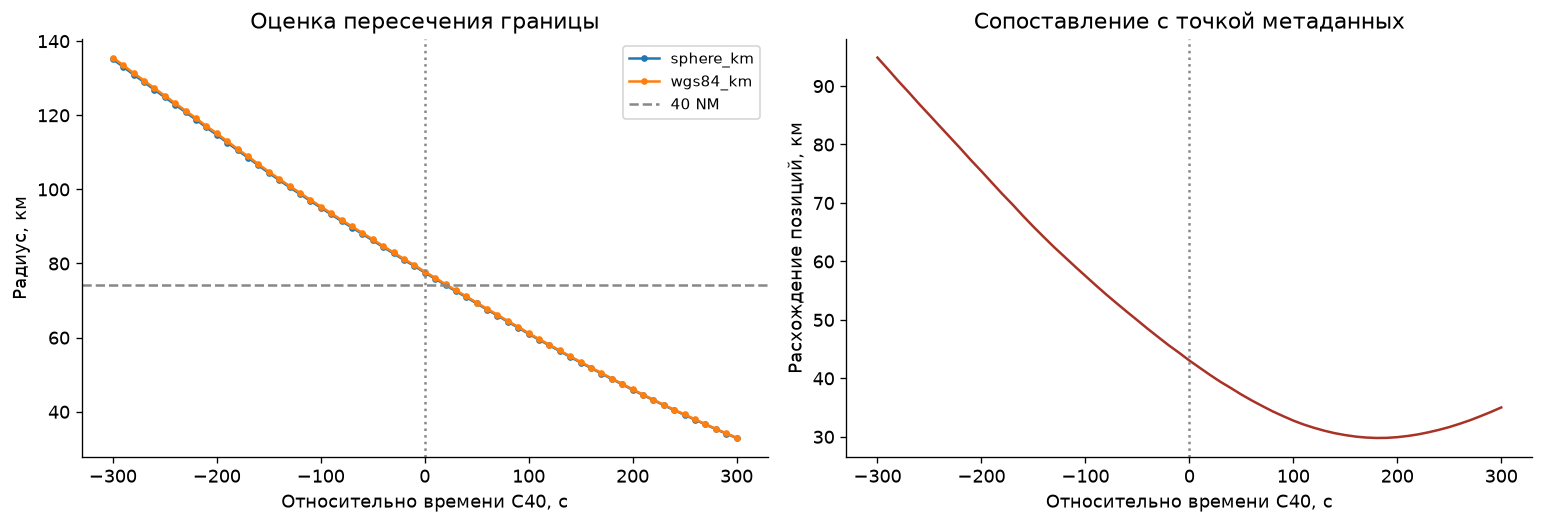

In [4]:
fig, axes = plt.subplots(1,2,figsize=(13,4.5))
# Сравниваем радиусы около времени метаданных
for model in ['sphere_km','wgs84_km']:
    axes[0].plot(local.offset_s,local[model],'.-',label=model)
axes[0].axhline(74.08,color='#888',linestyle='--',label='40 NM')
axes[0].axvline(0,color='#888',linestyle=':')
axes[0].set(xlabel='Относительно времени C40, с',ylabel='Радиус, км',title='Оценка пересечения границы')
axes[0].legend(fontsize=9)
# Отдельно показываем расстояние между источниками
axes[1].plot(local.offset_s,local.metadata_distance_m/1000,color='#A93226')
axes[1].axvline(0,color='#888',linestyle=':')
axes[1].set(xlabel='Относительно времени C40, с',ylabel='Расхождение позиций, км',title='Сопоставление с точкой метаданных')
plt.tight_layout()
plt.show()

## Что установлено и что остается открытым

Публичная последовательность дает оценку пересечения и свежести позиции. Расхождение около 43 км остается нерешенным: определение радиальной границы само по себе его не объясняет. OpenSky ADS-B не предполагается тождественным исходным CPR EUROCONTROL.

## Методические подробности и происхождение источников

# Публичная траектория EPWA – первый пилот

Из публичного часового архива OpenSky извлечен борт 489221. Сопоставление выполнено по ICAO24, времени и callsign. Использован восстановленный центр EPWA; исторический ARP еще не подтвержден независимо.

Пересечение 40 NM выделено по соседним наблюдениям снаружи и внутри границы. Линейная интерполяция расстояния во времени дает оценку, а не измеренный момент пересечения. Проверяем интервал и свежесть позиции. Это OpenSky ADS-B; совпадение с исходными CPR EUROCONTROL не предполагается. Результат этого рейса не переносится автоматически на EGCC.

Исходные наблюдения и геометрия сохранены локально в data/public_pilot, которая исключена из Git. Контрольная сумма и URL архива – в 05_public_pilot_download.json. Все записи основной базы сохраняются.

В момент метаданных существует наблюдение OpenSky с тем же ICAO24 и callsign, но расстояние между позициями около 43 км. Определение радиальной границы само по себе не объясняет пространственное несоответствие. Причина и источник расхождения пока не установлены. Проверку дополнить независимым историческим ARP и другими случаями.


---

Источник: https://opensky-network.org/datasets/ ; описание публичных state vectors: https://opensky-network.org/data/scientific . Геодезическая формула: Vincenty (1975), https://www.ngs.noaa.gov/PUBS_LIB/inverse.pdf . Воспроизведение: scripts/select_public_cases.py → probe_public_snapshots.py → fetch_public_pilot.py → analyze_public_pilot.py. Все результаты поиска относятся к публичным источникам; Trino не использовался.